# 03 — Hasil dan Analisis: Baseline vs Metode Pembanding (GTZAN)
**Pengolahan Sinyal Digital · Project Replikasi · Kelompok 1**

Notebook ini menganalisis hasil tujuh metode yang dihasilkan oleh notebook eksperimen (`02_pembanding`): baseline (BL), pendekatan A (MFCC + SVM/RF), pendekatan B (SpecAugment + label smoothing), dan tiga metode tambahan eksploratif (embedding YAMNet, fitur buatan tangan, dan gabungannya).

> **Semua angka, tabel, gambar, dan kalimat hasil dihasilkan oleh sel kode.** Sel markdown hanya berisi tujuan, desain analisis, dan definisi. Kalimat ringkasan dan keterbatasan (bagian 9 dan 10) dibangkitkan dari hasil yang dihitung. Notebook ini hanya memakai **CPU**.

**Cara menjalankan (Kaggle)**
1. *Add Input → Your Work → Notebook Output Files* → pilih **satu** notebook `02_pembanding` (versi tersimpan yang berisi `hasil_baseline.csv`, `hasil_A.csv`, `hasil_B.csv`, `hasil_C.csv`, `folds.json`, `segments.csv`, `pred_*`, dan `history`). Jangan menambahkan lebih dari satu sumber agar hasil dua run tidak tercampur.
2. Akselerator: **None**. Jalankan semua sel (*Run All*). Berkas hasil dikemas di `hasil_minggu3.zip` pada sel terakhir.

**Isi:** 1 Desain analisis · 2 Pemuatan dan validasi data · 3 Tabel hasil · 4 Uji antar fold · 5 Uji tingkat lagu (McNemar) · 6 Confusion matrix · 7 Sebaran skor (boxplot) · 8 Analisis kesalahan dan kurva validasi · 9 Ringkasan hasil · 10 Keterbatasan dan konsistensi

## 1. Desain analisis
| Pertanyaan | Metode |
|---|---|
| Seberapa baik tiap metode, dan seberapa stabil antar fold? | Tabel skor per fold, rata-rata, dan simpangan baku untuk akurasi segmen, F1-macro, dan akurasi lagu |
| Apakah selisih antar metode lebih dari kebetulan? | Paired t-test antar fold (pembagian data identik), CI 95%, effect size d_z, koreksi Holm, dan uji Wilcoxon sebagai pembanding non-parametrik |
| Apakah kesimpulan sama pada tingkat lagu? | Uji McNemar pada prediksi lagu (voting mayoritas segmen) yang digabung dari seluruh fold |
| Genre mana yang dibantu atau dirugikan? | Confusion matrix gabungan, recall per genre, boxplot F1 per genre lintas fold |
| Bagaimana proses belajarnya? | Kurva akurasi dan selisih train–val rata-rata lintas fold (BL dan B) |
| Apakah metode yang berbeda salah pada segmen yang sama? | Tabel tumpang tindih benar/salah dan pasangan genre yang paling sering tertukar |

**Dua keluarga perbandingan** (koreksi Holm diterapkan **terpisah** dalam tiap keluarga dan tiap metrik):
- *Direncanakan:* pendekatan A dan B terhadap baseline dan antar pendekatan.
- *Eksploratif:* tiga metode tambahan (ditambahkan setelah hasil awal diketahui; metode C memakai data eksternal).

Unit uji statistik adalah **fold**. Skor kedua metode dipasangkan per fold. Jika notebook eksperimen memakai lebih dari satu seed, skor tiap fold adalah rata-rata antar seed.

## 2. Pemuatan dan validasi data

In [1]:
import os, glob, json, zipfile, platform
import importlib.metadata as md
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import confusion_matrix, f1_score
from IPython.display import display

N_FOLD, ALPHA, TOP_K = 5, 0.05, 5
WORK_DIR = "/kaggle/working"
REF  = ["BL", "B", "A_SVM", "A_RF"]
BARU = ["C_YAM", "D_HAND", "CD_GAB"]
METODE = REF + BARU
NAMA = {"BL": "BL (CNN+Bi-GRU)", "B": "B (BL+SpecAug+LS)", "A_SVM": "A_SVM (MFCC+SVM)", "A_RF": "A_RF (MFCC+RF)",
        "C_YAM": "C_YAM (YAMNet+SVM)", "D_HAND": "D_HAND (buatan tangan+SVM)", "CD_GAB": "CD_GAB (gabungan+SVM)"}
PRED_SUB = {"BL": ("pred_baseline", "BL"), "A_SVM": ("pred_A", "A_SVM"), "A_RF": ("pred_A", "A_RF"), "B": ("pred_B", "B"),
            "C_YAM": ("pred_C", "C_YAM"), "D_HAND": ("pred_C", "D_HAND"), "CD_GAB": ("pred_C", "CD_GAB")}
PLAN  = [("B", "BL"), ("BL", "A_SVM"), ("BL", "A_RF"), ("B", "A_SVM"), ("B", "A_RF"), ("A_SVM", "A_RF")]
EKSPL = [("CD_GAB", "BL"), ("C_YAM", "BL"), ("D_HAND", "BL"), ("CD_GAB", "B"), ("C_YAM", "B"),
         ("CD_GAB", "C_YAM"), ("CD_GAB", "D_HAND"), ("C_YAM", "D_HAND"), ("D_HAND", "A_SVM")]
KELUARGA = [("direncanakan", PLAN), ("eksploratif", EKSPL)]
warna = {"BL": "#6b7280", "B": "#2563eb", "A_SVM": "#d97706", "A_RF": "#f0b45a", "C_YAM": "#16a34a", "D_HAND": "#a855f7", "CD_GAB": "#dc2626"}
pd.set_option("display.width", 220, "display.max_columns", 30)

kandidat = sorted(glob.glob("/kaggle/input/**/hasil_baseline.csv", recursive=True))
assert kandidat, "hasil_baseline.csv tidak ditemukan. Tambahkan output notebook eksperimen lewat Add Input."
assert len(kandidat) == 1, f"Ditemukan {len(kandidat)} sumber hasil; sisakan satu saja agar tidak tercampur: {kandidat}"
SRC = os.path.dirname(kandidat[0])
for nm in ("hasil_A.csv", "hasil_B.csv", "hasil_C.csv", "folds.json", "segments.csv"):
    assert os.path.exists(os.path.join(SRC, nm)), f"{nm} tidak ada di {SRC}; gunakan output notebook 02_pembanding versi terbaru."
print("Sumber hasil:", SRC); print("Isi:", sorted(os.listdir(SRC)))

Sumber hasil: /kaggle/input/notebooks/mohammadadibalfiyan/02-pembanding-merge
Isi: ['__notebook__.ipynb', '__output__.json', '__results__.html', '__results___files', 'custom.css', 'fig_confusion_m2.png', 'fig_diagram_alur.png', 'fig_kurva_learning_fold1.png', 'fitur_buatan_tangan.npy', 'fitur_yamnet.npy', 'folds.json', 'hasil_A.csv', 'hasil_B.csv', 'hasil_C.csv', 'hasil_baseline.csv', 'hasil_minggu2.zip', 'history', 'pred_A', 'pred_B', 'pred_C', 'pred_baseline', 'requirements_m2.txt', 'segments.csv', 'tabel_konfigurasi_m2.csv', 'tabel_m2_f1_macro.csv', 'tabel_m2_recall_per_genre.csv', 'tabel_m2_ringkasan.csv', 'tabel_m2_test_acc.csv', 'tabel_m2_track_acc.csv', 'uji_berpasangan_m2.csv']


In [2]:
semua_raw = pd.concat([pd.read_csv(os.path.join(SRC, f"hasil_{x}.csv")) for x in ("baseline", "A", "B", "C")])
semua_raw = semua_raw[semua_raw.metode.isin(METODE)].drop_duplicates(["metode", "fold", "seed"], keep="last")
SEEDS_ADA = {m: sorted(semua_raw[semua_raw.metode == m].seed.unique().tolist()) for m in METODE}
print("Seed per metode:", SEEDS_ADA)
semua = semua_raw.groupby(["metode", "fold"], as_index=False)[["test_acc", "f1_macro", "track_acc"]].mean()
for m in METODE:
    assert sorted(semua[semua.metode == m].fold.tolist()) == list(range(1, N_FOLD + 1)), f"{m}: fold tidak lengkap"

seg = pd.read_csv(os.path.join(SRC, "segments.csv"))
GENRES = seg.groupby("label").genre.first().sort_index().tolist()
with open(os.path.join(SRC, "folds.json")) as f:
    FOLDS = {int(k): {p: np.array(v) for p, v in d.items()} for k, d in json.load(f).items()}
test_idx = np.concatenate([FOLDS[k]["test"] for k in FOLDS])
assert len(test_idx) == len(seg) and len(np.unique(test_idx)) == len(seg), "data test tiap fold harus menutupi semua segmen tepat sekali"
print(f"Segmen: {len(seg)} | Lagu: {seg.track_id.nunique()} | Genre: {len(GENRES)} {GENRES}")

def muat_pred(m, k, seed):
    folder, prefix = PRED_SUB[m]
    a = np.load(os.path.join(SRC, folder, f"{prefix}_fold{k}_s{seed}.npy")); return a[0].astype(int), a[1].astype(int)

# validasi silang: label pada file prediksi = label sebenarnya, dan akurasi dari prediksi = akurasi pada CSV
maks_selisih = 0.0
for _, r in semua_raw.iterrows():
    y, p = muat_pred(r.metode, int(r.fold), int(r.seed))
    assert (y == seg.label.values[FOLDS[int(r.fold)]["test"]]).all(), f"label tidak cocok: {r.metode} fold {r.fold}"
    maks_selisih = max(maks_selisih, abs((y == p).mean() - r.test_acc))
assert maks_selisih < 1e-3, f"akurasi dari prediksi tidak cocok dengan CSV (selisih {maks_selisih})"
print(f"Validasi lolos: {len(semua_raw)} run; selisih akurasi CSV vs prediksi maksimal {maks_selisih:.5f}")

Seed per metode: {'BL': [42, 43], 'B': [42, 43], 'A_SVM': [42], 'A_RF': [42], 'C_YAM': [42], 'D_HAND': [42], 'CD_GAB': [42]}
Segmen: 9990 | Lagu: 999 | Genre: 10 ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Validasi lolos: 45 run; selisih akurasi CSV vs prediksi maksimal 0.00004


## 3. Tabel hasil lintas metode dan lintas fold

In [3]:
METRIK = {"test_acc": "Akurasi segmen", "f1_macro": "F1-macro", "track_acc": "Akurasi lagu"}
TABEL = {}
for col, nama in METRIK.items():
    pv = semua.pivot(index="metode", columns="fold", values=col).loc[METODE] * 100
    pv.columns = [f"Fold {c}" for c in pv.columns]
    pv["Rata-rata"] = pv.iloc[:, :N_FOLD].mean(axis=1)
    pv["SD"]        = pv.iloc[:, :N_FOLD].std(axis=1, ddof=1)
    TABEL[nama] = pv.round(2)
    print(f"\n{nama} (%)"); display(TABEL[nama])
    TABEL[nama].to_csv(os.path.join(WORK_DIR, f"tabel_m3_{col}.csv"))
RINGKAS = pd.DataFrame({nama: [f"{TABEL[nama].loc[m, 'Rata-rata']:.2f} ± {TABEL[nama].loc[m, 'SD']:.2f}" for m in METODE]
                        for nama in METRIK.values()}, index=[NAMA[m] for m in METODE])
print(f"\nRingkasan {N_FOLD} fold (rata-rata ± SD, %)"); display(RINGKAS)
RINGKAS.to_csv(os.path.join(WORK_DIR, "tabel_m3_ringkasan.csv"))


Akurasi segmen (%)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Rata-rata,SD
metode,,,,,,,
BL,82.38,81.45,80.05,82.38,80.46,81.34,1.07
B,82.88,84.15,80.32,82.38,80.76,82.10,1.57
A_SVM,66.00,64.75,68.00,71.45,65.18,67.08,2.75
A_RF,64.50,61.85,66.45,69.10,62.21,64.82,3.03
C_YAM,78.25,78.65,75.50,83.10,79.25,78.95,2.73
D_HAND,75.70,74.05,74.40,76.00,73.27,74.68,1.15
CD_GAB,82.25,82.55,80.80,87.05,83.32,83.19,2.34



F1-macro (%)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Rata-rata,SD
metode,,,,,,,
BL,82.30,81.38,79.97,82.30,80.46,81.29,1.06
B,82.78,84.09,80.24,82.34,80.72,82.03,1.57
A_SVM,65.72,64.35,67.57,71.36,64.69,66.74,2.87
A_RF,63.69,60.99,65.38,68.45,61.13,63.93,3.13
C_YAM,78.26,78.47,75.30,82.83,79.00,78.77,2.69
D_HAND,75.53,73.54,74.19,75.93,72.99,74.44,1.26
CD_GAB,82.27,82.33,80.49,86.95,83.13,83.03,2.39



Akurasi lagu (%)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Rata-rata,SD
metode,,,,,,,
BL,87.00,86.25,84.50,88.75,85.18,86.34,1.66
B,88.25,88.75,83.75,87.00,84.92,86.54,2.15
A_SVM,78.00,74.00,77.00,81.50,72.86,76.67,3.42
A_RF,72.50,68.00,71.50,76.00,69.35,71.47,3.09
C_YAM,86.50,84.50,82.50,90.50,86.93,86.19,2.99
D_HAND,82.50,81.00,83.00,86.50,80.90,82.78,2.27
CD_GAB,90.50,89.50,87.50,93.00,90.95,90.29,2.01



Ringkasan 5 fold (rata-rata ± SD, %)


,Akurasi segmen,F1-macro,Akurasi lagu
BL (CNN+Bi-GRU),81.34 ± 1.07,81.29 ± 1.06,86.34 ± 1.66
B (BL+SpecAug+LS),82.10 ± 1.57,82.03 ± 1.57,86.54 ± 2.15
A_SVM (MFCC+SVM),67.08 ± 2.75,66.74 ± 2.87,76.67 ± 3.42
A_RF (MFCC+RF),64.82 ± 3.03,63.93 ± 3.13,71.47 ± 3.09
C_YAM (YAMNet+SVM),78.95 ± 2.73,78.77 ± 2.69,86.19 ± 2.99
D_HAND (buatan tangan+SVM),74.68 ± 1.15,74.44 ± 1.26,82.78 ± 2.27
CD_GAB (gabungan+SVM),83.19 ± 2.34,83.03 ± 2.39,90.29 ± 2.01


## 4. Uji signifikansi antar fold
Paired t-test dua sisi pada skor per fold, CI 95% selisih rata-rata (distribusi t), effect size *d_z*, koreksi Holm **terpisah per keluarga dan per metrik**, dan uji Wilcoxon signed-rank sebagai pembanding non-parametrik.

In [4]:
def skor(m, col): return semua[semua.metode == m].sort_values("fold")[col].values * 100

def uji(a, b, col, kel):
    x, y = skor(a, col), skor(b, col); d, n = x - y, len(x); sd = d.std(ddof=1)
    if sd == 0:      # selisih identik di semua fold: uji t tidak terdefinisi
        t_stat, p, h, dz = (0.0, 1.0, 0.0, np.nan) if d.mean() == 0 else (np.inf * np.sign(d.mean()), 0.0, 0.0, np.nan)
    else:
        t = stats.ttest_rel(x, y); t_stat, p = t.statistic, t.pvalue
        h, dz = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n), d.mean() / sd
    try: pw = stats.wilcoxon(x, y).pvalue
    except ValueError: pw = np.nan
    return dict(keluarga=kel, perbandingan=f"{a} vs {b}", metrik=METRIK[col], selisih=d.mean(), ci95_bawah=d.mean() - h, ci95_atas=d.mean() + h,
                t=t_stat, df=n - 1, p=p, cohen_dz=dz, p_wilcoxon=pw, fold_a_unggul=int((d > 0).sum()), n_fold=n)

def holm(p):
    p = np.asarray(p); adj, run = np.empty(len(p)), 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(run, 1.0)
    return adj

UJI = pd.DataFrame([uji(a, b, c, kel) for c in METRIK for kel, ps in KELUARGA for a, b in ps])
UJI["p_holm"] = UJI.groupby(["keluarga", "metrik"]).p.transform(lambda s: holm(s.values))
UJI["signifikan"] = np.where(UJI.p_holm < ALPHA, "ya", "tidak")
UJI.to_csv(os.path.join(WORK_DIR, "uji_berpasangan_m3.csv"), index=False)
for nama in METRIK.values():
    for kel, _ in KELUARGA:
        print(f"\n{nama}, keluarga {kel}:")
        display(UJI[(UJI.metrik == nama) & (UJI.keluarga == kel)].drop(columns=["metrik", "keluarga"]).round(4).set_index("perbandingan"))


Akurasi segmen, keluarga direncanakan:


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,p_wilcoxon,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,,
B vs BL,0.755,-0.6130,2.1230,1.5323,4,0.2002,0.6853,0.1250,4,5,0.2002,tidak
BL vs A_SVM,14.265,11.0115,17.5185,12.1734,4,0.0003,5.4441,0.0625,5,5,0.0013,ya
BL vs A_RF,16.519,12.9335,20.1045,12.7915,4,0.0002,5.7205,0.0625,5,5,0.0013,ya
B vs A_SVM,15.020,10.7654,19.2746,9.8016,4,0.0006,4.3834,0.0625,5,5,0.0020,ya
B vs A_RF,17.274,12.6433,21.9047,10.3571,4,0.0005,4.6319,0.0625,5,5,0.0020,ya
A_SVM vs A_RF,2.254,1.3753,3.1327,7.1219,4,0.0021,3.1850,0.0625,5,5,0.0041,ya



Akurasi segmen, keluarga eksploratif:


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,p_wilcoxon,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,,
CD_GAB vs BL,1.853,-0.5260,4.2320,2.1626,4,0.0966,0.9671,0.1250,4,5,0.2284,tidak
C_YAM vs BL,-2.391,-5.0937,0.3117,-2.4563,4,0.0700,-1.0985,0.1250,1,5,0.2284,tidak
D_HAND vs BL,-6.657,-7.5183,-5.7957,-21.4590,4,0.0000,-9.5967,0.0625,0,5,0.0003,ya
CD_GAB vs B,1.098,-2.0422,4.2382,0.9708,4,0.3866,0.4342,0.6250,3,5,0.3866,tidak
C_YAM vs B,-3.146,-6.4443,0.1523,-2.6482,4,0.0571,-1.1843,0.1250,1,5,0.2284,tidak
CD_GAB vs C_YAM,4.244,3.5069,4.9811,15.9854,4,0.0001,7.1489,0.0625,5,5,0.0007,ya
CD_GAB vs D_HAND,8.510,5.9415,11.0785,9.1988,4,0.0008,4.1138,0.0625,5,5,0.0054,ya
C_YAM vs D_HAND,4.266,1.2214,7.3106,3.8903,4,0.0177,1.7398,0.0625,5,5,0.0884,tidak
D_HAND vs A_SVM,7.608,4.9535,10.2625,7.9574,4,0.0014,3.5587,0.0625,5,5,0.0081,ya



F1-macro, keluarga direncanakan:


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,p_wilcoxon,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,,
B vs BL,0.748,-0.6238,2.1198,1.5140,4,0.2046,0.6771,0.0625,5,5,0.2046,tidak
BL vs A_SVM,14.548,11.1797,17.9163,11.9917,4,0.0003,5.3629,0.0625,5,5,0.0014,ya
BL vs A_RF,17.358,13.7038,21.0122,13.1885,4,0.0002,5.8981,0.0625,5,5,0.0011,ya
B vs A_SVM,15.296,10.9558,19.6362,9.7850,4,0.0006,4.3760,0.0625,5,5,0.0018,ya
B vs A_RF,18.106,13.4450,22.7670,10.7853,4,0.0004,4.8233,0.0625,5,5,0.0017,ya
A_SVM vs A_RF,2.810,1.9615,3.6585,9.1951,4,0.0008,4.1122,0.0625,5,5,0.0018,ya


... (2 outputs left out)


Akurasi lagu, keluarga direncanakan:


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,p_wilcoxon,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,,
B vs BL,0.200,-1.8870,2.2870,0.2661,4,0.8033,0.1190,1.0000,2,5,0.8033,tidak
BL vs A_SVM,9.663,6.5796,12.7464,8.7011,4,0.0010,3.8913,0.0625,5,5,0.0035,ya
BL vs A_RF,14.865,12.0565,17.6735,14.6953,4,0.0001,6.5720,0.0625,5,5,0.0007,ya
B vs A_SVM,9.863,5.1509,14.5751,5.8114,4,0.0044,2.5990,0.0625,5,5,0.0087,ya
B vs A_RF,15.065,10.3574,19.7726,8.8851,4,0.0009,3.9735,0.0625,5,5,0.0035,ya
A_SVM vs A_RF,5.202,3.9972,6.4068,11.9878,4,0.0003,5.3611,0.0625,5,5,0.0014,ya



Akurasi lagu, keluarga eksploratif:


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,p_wilcoxon,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,,
CD_GAB vs BL,3.955,2.5646,5.3454,7.8978,4,0.0014,3.5320,0.0625,5,5,0.0094,ya
C_YAM vs BL,-0.149,-2.4169,2.1189,-0.1824,4,0.8641,-0.0816,0.8750,2,5,1.0000,tidak
D_HAND vs BL,-3.555,-5.5388,-1.5712,-4.9754,4,0.0076,-2.2251,0.0625,0,5,0.0381,ya
CD_GAB vs B,3.755,0.8771,6.6329,3.6227,4,0.0223,1.6201,0.0625,5,5,0.0892,tidak
C_YAM vs B,-0.349,-4.1936,3.4956,-0.2520,4,0.8134,-0.1127,1.0000,2,5,1.0000,tidak
CD_GAB vs C_YAM,4.104,2.8322,5.3758,8.9596,4,0.0009,4.0068,0.0625,5,5,0.0069,ya
CD_GAB vs D_HAND,7.510,4.8942,10.1258,7.9713,4,0.0013,3.5649,0.0625,5,5,0.0094,ya
C_YAM vs D_HAND,3.406,0.4379,6.3741,3.1861,4,0.0333,1.4248,0.1250,4,5,0.1000,tidak
D_HAND vs A_SVM,6.108,4.3137,7.9023,9.4512,4,0.0007,4.2267,0.0625,5,5,0.0063,ya


## 5. Uji tingkat lagu (McNemar)
Prediksi lagu diperoleh dari **voting mayoritas** prediksi segmen (seri dimenangkan kelas dengan indeks terkecil), digabung dari seluruh fold: tiap lagu menjadi data test tepat sekali. Jika ada beberapa seed, dipakai seed pertama yang tersedia. McNemar eksak (binomial dua sisi) membandingkan lagu yang hanya benar pada satu metode, dengan koreksi Holm per keluarga. Uji ini memperlakukan lagu sebagai sampel independen dan hanya menilai satu model terlatih per fold, sehingga **tidak menangkap variasi antar-run pelatihan**.

In [5]:
trk_seg = seg.track_id.values
def vote(seg_idx, preds):
    d = pd.DataFrame({"t": trk_seg[seg_idx], "p": preds})
    return d.groupby("t").p.agg(lambda s: np.bincount(s).argmax())

LAGU = {}
for m in METODE:
    parts = []
    for k in range(1, N_FOLD + 1):
        s0 = SEEDS_ADA[m][0]; y, p = muat_pred(m, k, s0)
        yl = pd.Series(seg.label.values[FOLDS[k]["test"]], index=trk_seg[FOLDS[k]["test"]]).groupby(level=0).first()
        parts.append(pd.DataFrame({"y": yl, "pred": vote(FOLDS[k]["test"], p)}))
    LAGU[m] = pd.concat(parts).sort_index()
ref = LAGU["BL"].index
for m in METODE: assert LAGU[m].index.equals(ref) and (LAGU[m].y.values == LAGU["BL"].y.values).all()
BENAR = {m: (LAGU[m].pred.values == LAGU[m].y.values) for m in METODE}
print(f"Jumlah lagu: {len(ref)}")
print("Akurasi lagu (voting, gabungan fold): " + " | ".join(f"{m} {BENAR[m].mean()*100:.2f}%" for m in METODE))

rows = []
for kel, ps in KELUARGA:
    sub = []
    for a, b in ps:
        n10 = int((BENAR[a] & ~BENAR[b]).sum()); n01 = int((~BENAR[a] & BENAR[b]).sum())
        p = stats.binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if n10 + n01 > 0 else 1.0
        sub.append(dict(keluarga=kel, perbandingan=f"{a} vs {b}", benar_hanya_a=n10, benar_hanya_b=n01, p_mcnemar=p))
    sub = pd.DataFrame(sub); sub["p_holm"] = holm(sub.p_mcnemar.values); rows.append(sub)
MCN = pd.concat(rows, ignore_index=True)
MCN["signifikan"] = np.where(MCN.p_holm < ALPHA, "ya", "tidak")
MCN.to_csv(os.path.join(WORK_DIR, "uji_mcnemar_m3.csv"), index=False)
for kel, _ in KELUARGA:
    print(f"\nKeluarga {kel}:"); display(MCN[MCN.keluarga == kel].drop(columns="keluarga").round(4).set_index("perbandingan"))

Jumlah lagu: 999
Akurasi lagu (voting, gabungan fold): BL 87.49% | B 86.69% | A_SVM 75.68% | A_RF 71.37% | C_YAM 85.49% | D_HAND 81.18% | CD_GAB 89.59%

Keluarga direncanakan:


,benar_hanya_a,benar_hanya_b,p_mcnemar,p_holm,signifikan
perbandingan,,,,,
B vs BL,44,52,0.4752,0.4752,tidak
BL vs A_SVM,160,42,0.0000,0.0000,ya
BL vs A_RF,196,35,0.0000,0.0000,ya
B vs A_SVM,156,46,0.0000,0.0000,ya
B vs A_RF,189,36,0.0000,0.0000,ya
A_SVM vs A_RF,103,60,0.0009,0.0019,ya



Keluarga eksploratif:


,benar_hanya_a,benar_hanya_b,p_mcnemar,p_holm,signifikan
perbandingan,,,,,
CD_GAB vs BL,70,49,0.0663,0.1989,tidak
C_YAM vs BL,66,86,0.1230,0.2460,tidak
D_HAND vs BL,53,116,0.0000,0.0000,ya
CD_GAB vs B,76,47,0.0113,0.0451,ya
C_YAM vs B,73,85,0.3816,0.3816,tidak
CD_GAB vs C_YAM,53,12,0.0000,0.0000,ya
CD_GAB vs D_HAND,111,27,0.0000,0.0000,ya
C_YAM vs D_HAND,104,61,0.0010,0.0051,ya
D_HAND vs A_SVM,106,51,0.0000,0.0001,ya


## 6. Confusion matrix gabungan dan recall per genre
Prediksi seluruh fold (dan seluruh seed) digabung; tiap baris dinormalisasi oleh jumlah segmen kelas sebenarnya.

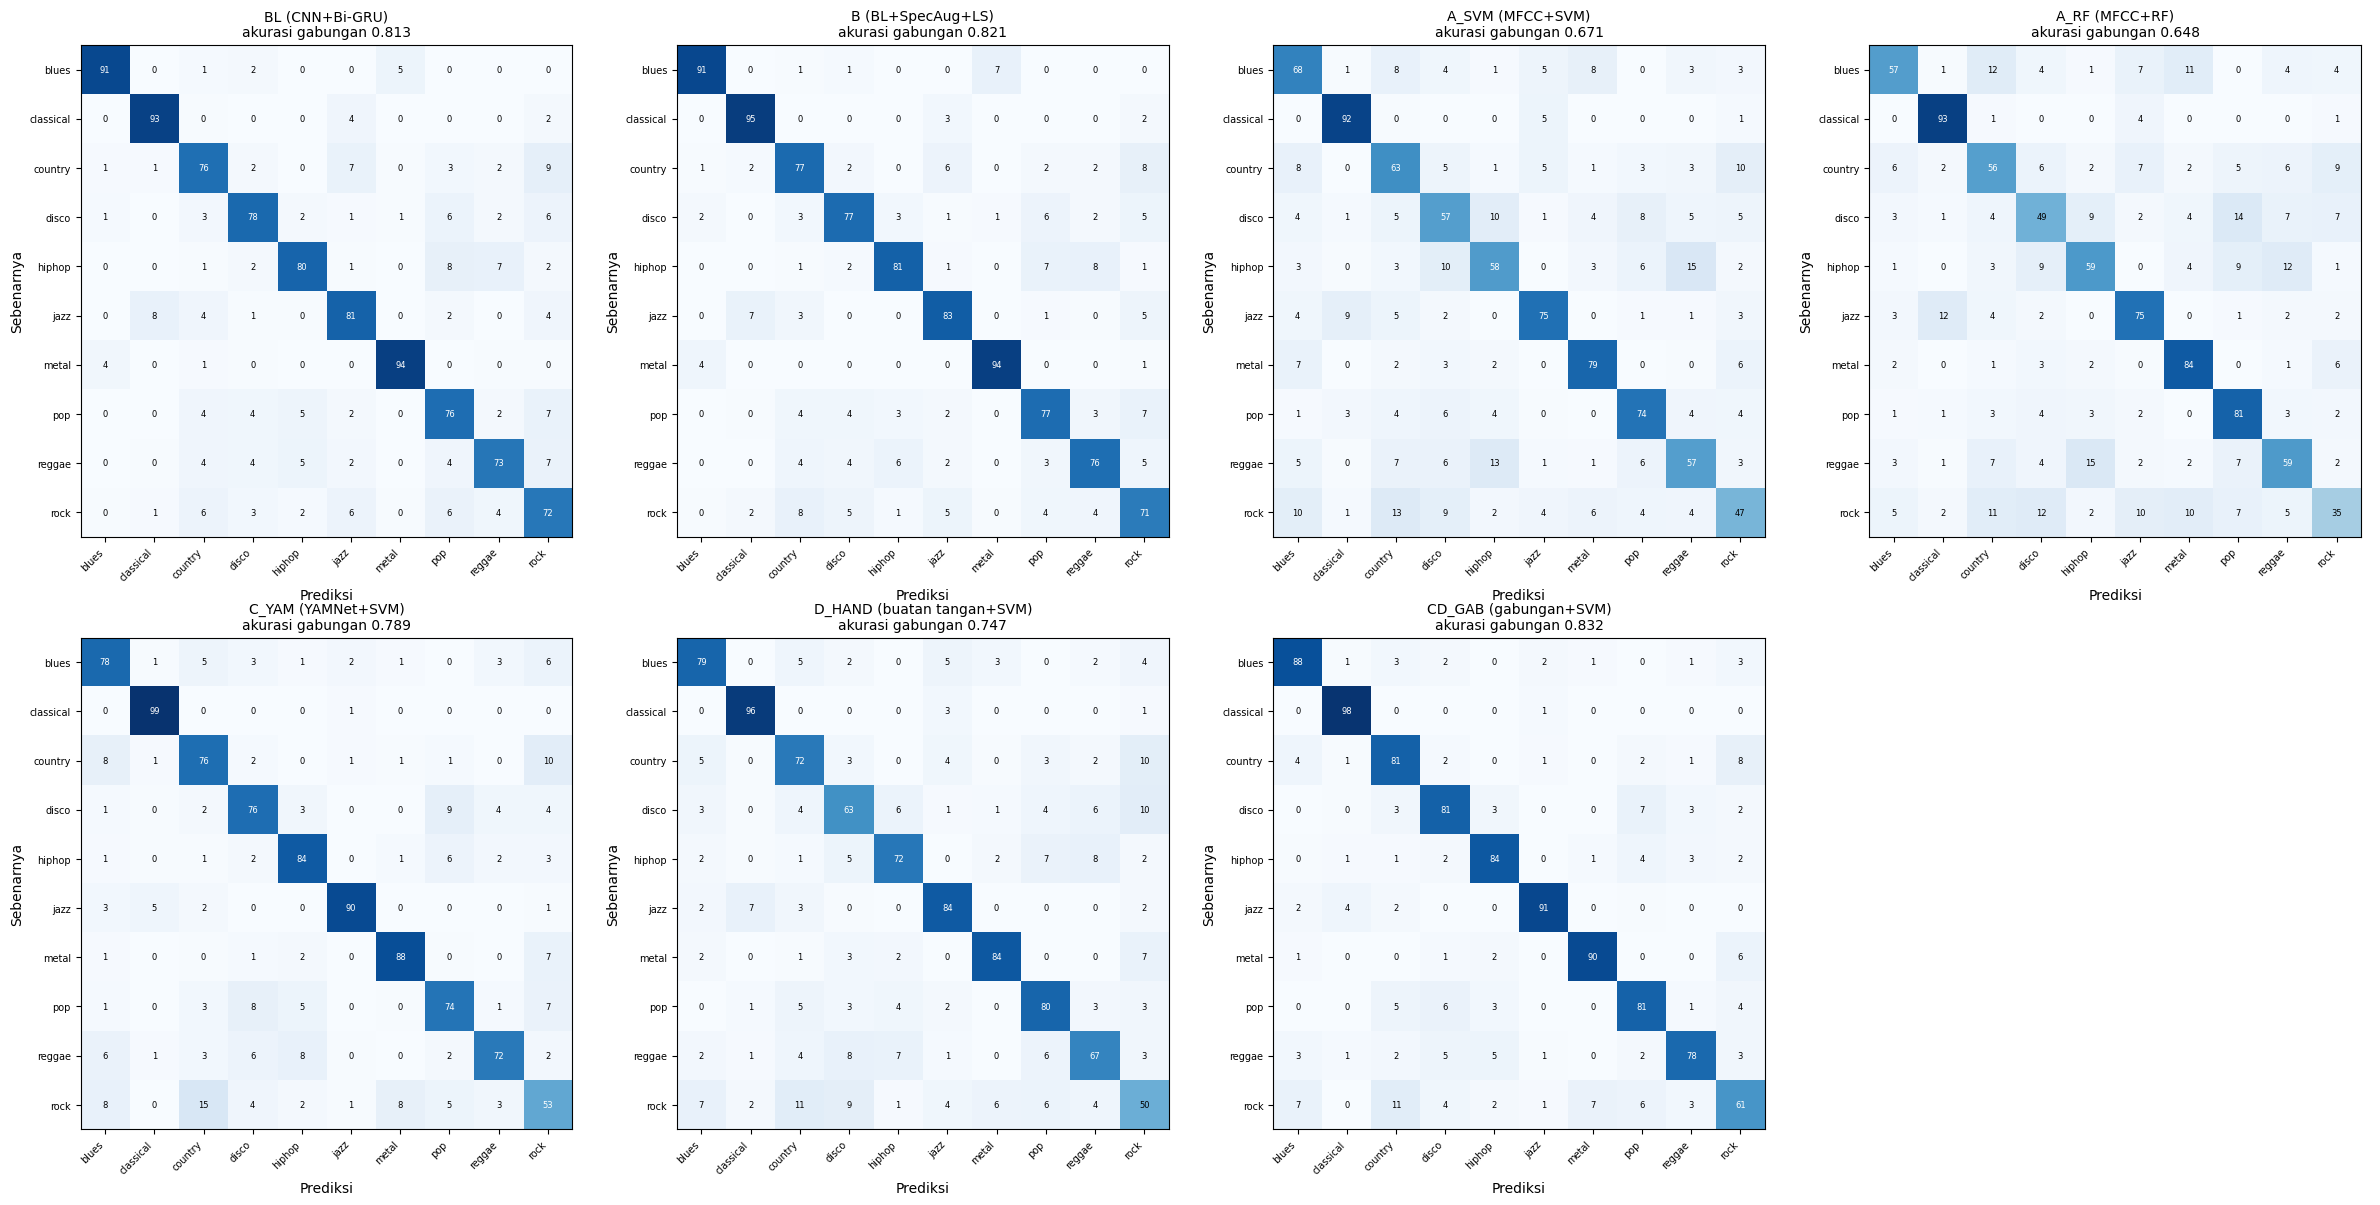

Recall per genre (%):


,BL,B,A_SVM,A_RF,C_YAM,D_HAND,CD_GAB,B - BL,CD_GAB - BL
blues,90.6,90.6,68.0,57.2,77.9,79.4,87.5,0.0,-3.1
classical,93.2,94.7,92.5,93.4,98.7,95.7,98.3,1.5,5.1
country,75.5,77.4,63.4,56.3,76.1,71.5,81.1,1.9,5.6
disco,78.0,77.0,56.7,48.8,76.5,62.8,80.9,-1.0,2.9
hiphop,79.8,81.2,58.2,59.2,83.9,72.3,84.4,1.4,4.6
jazz,80.8,82.6,75.4,74.9,89.7,83.9,91.0,1.8,10.2
metal,94.1,94.0,79.1,83.7,88.4,84.4,89.7,-0.1,-4.4
pop,76.2,76.8,74.1,80.8,73.6,79.6,80.6,0.6,4.4
reggae,72.9,75.9,56.9,58.9,71.7,67.4,77.9,3.0,5.0
rock,72.3,70.8,46.6,35.1,53.1,49.9,60.6,-1.5,-11.7


In [6]:
def pred_gabungan(m):
    ys, ps = [], []
    for k in range(1, N_FOLD + 1):
        for s in SEEDS_ADA[m]:
            y, p = muat_pred(m, k, s); ys.append(y); ps.append(p)
    return np.concatenate(ys), np.concatenate(ps)

CM, RECALL = {}, {}
fig, axes = plt.subplots(2, 4, figsize=(24, 12)); axes = axes.ravel()
for ax_, m in zip(axes, METODE):
    y, p = pred_gabungan(m)
    cm = confusion_matrix(y, p, labels=range(len(GENRES))); cmn = cm / cm.sum(axis=1, keepdims=True)
    CM[m] = cm; RECALL[m] = np.diag(cmn)
    ax_.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax_.set_title(f"{NAMA[m]}\nakurasi gabungan {np.trace(cm)/cm.sum():.3f}", fontsize=10)
    ax_.set_xticks(range(len(GENRES))); ax_.set_yticks(range(len(GENRES)))
    ax_.set_xticklabels(GENRES, rotation=45, ha="right", fontsize=7); ax_.set_yticklabels(GENRES, fontsize=7)
    ax_.set_xlabel("Prediksi"); ax_.set_ylabel("Sebenarnya")
    for i in range(len(GENRES)):
        for j in range(len(GENRES)):
            ax_.text(j, i, f"{cmn[i, j]*100:.0f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
for ax_ in axes[len(METODE):]: ax_.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_confusion_m3.png"), dpi=200, bbox_inches="tight"); plt.show()

REC = pd.DataFrame(RECALL, index=GENRES).mul(100).round(1)[METODE]
REC["B - BL"] = (REC["B"] - REC["BL"]).round(1)
REC["CD_GAB - BL"] = (REC["CD_GAB"] - REC["BL"]).round(1)
print("Recall per genre (%):"); display(REC)
REC.to_csv(os.path.join(WORK_DIR, "tabel_m3_recall_per_genre.csv"))

## 7. Sebaran skor lintas fold (boxplot)
Setiap kotak dibangun dari **sejumlah nilai fold yang sama dengan jumlah fold** (titik-titiknya ditampilkan), sehingga sebaran ini bersifat deskriptif dan bukan perkiraan distribusi populasi.

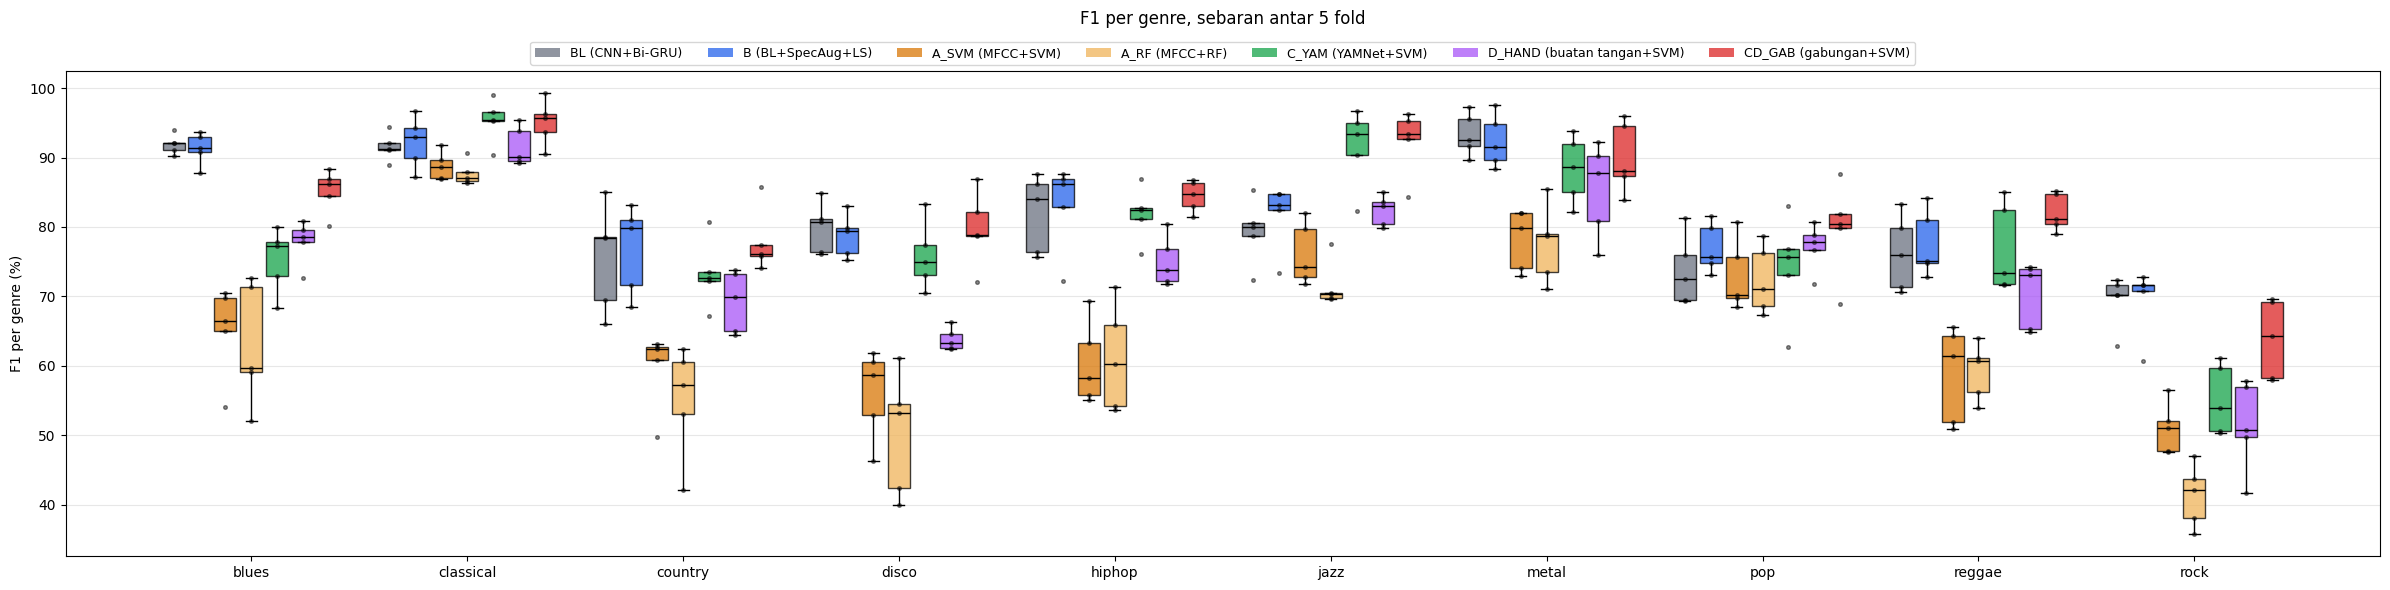

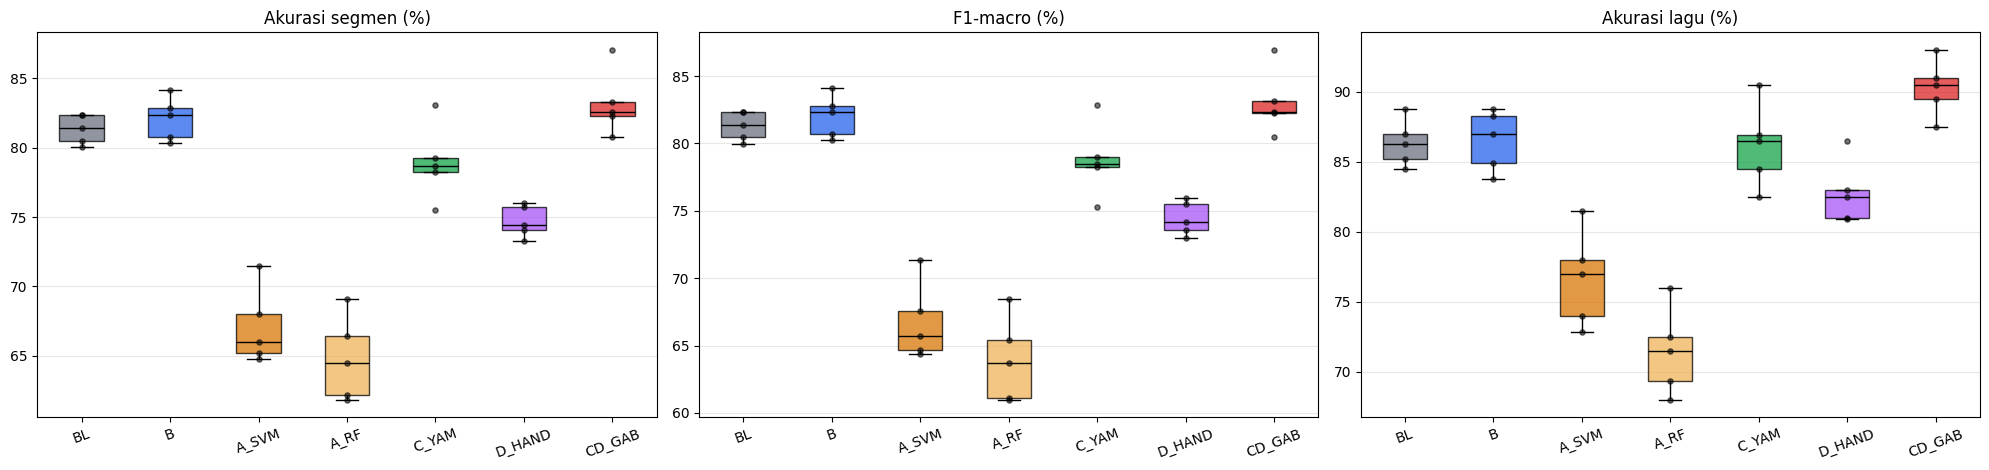

In [7]:
F1G = {m: np.zeros((N_FOLD, len(GENRES))) for m in METODE}      # F1 per genre per fold (rata-rata antar seed)
for m in METODE:
    for k in range(1, N_FOLD + 1):
        f1s = []
        for s in SEEDS_ADA[m]:
            y, p = muat_pred(m, k, s); f1s.append(f1_score(y, p, labels=range(len(GENRES)), average=None, zero_division=0))
        F1G[m][k - 1] = np.mean(f1s, axis=0) * 100

fig, ax = plt.subplots(figsize=(24, 6)); lebar = 0.12
for i, m in enumerate(METODE):
    pos = np.arange(len(GENRES)) + (i - (len(METODE) - 1) / 2) * lebar
    bp = ax.boxplot([F1G[m][:, g] for g in range(len(GENRES))], positions=pos, widths=lebar * 0.85, patch_artist=True,
                    medianprops=dict(color="black"), showfliers=False)
    for patch in bp["boxes"]: patch.set(facecolor=warna[m], alpha=0.75)
    for g in range(len(GENRES)): ax.scatter(np.full(N_FOLD, pos[g]), F1G[m][:, g], s=7, color="k", alpha=0.45, zorder=3)
ax.set_xticks(range(len(GENRES))); ax.set_xticklabels(GENRES); ax.set_ylabel("F1 per genre (%)"); ax.grid(axis="y", alpha=0.3)
ax.set_title(f"F1 per genre, sebaran antar {N_FOLD} fold", pad=34)
ax.legend([plt.Rectangle((0, 0), 1, 1, fc=warna[m], alpha=0.75) for m in METODE], [NAMA[m] for m in METODE], ncol=len(METODE), loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_boxplot_f1_genre.png"), dpi=200); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(20, 4.8))
for ax_, (col, nama) in zip(axs, METRIK.items()):
    data = [skor(m, col) for m in METODE]
    bp = ax_.boxplot(data, patch_artist=True, medianprops=dict(color="black"), showfliers=False)
    for patch, m in zip(bp["boxes"], METODE): patch.set(facecolor=warna[m], alpha=0.75)
    for i, d_ in enumerate(data, 1): ax_.scatter(np.full(len(d_), i), d_, s=14, color="k", alpha=0.55, zorder=3)
    ax_.set_xticks(range(1, len(METODE) + 1)); ax_.set_xticklabels(METODE, rotation=20); ax_.set_title(nama + " (%)"); ax_.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_boxplot_metrik_fold.png"), dpi=200); plt.show()

## 8. Analisis kesalahan dan kurva validasi

In [8]:
# 8.1 pasangan genre yang paling sering tertukar (per segmen, gabungan fold)
def konfusi_teratas(m, k=TOP_K):
    cm = CM[m].astype(float); n = cm.sum(axis=1, keepdims=True); rows = []
    for i in range(len(GENRES)):
        for j in range(len(GENRES)):
            if i != j: rows.append((GENRES[i], GENRES[j], cm[i, j] / n[i, 0] * 100))
    return pd.DataFrame(rows, columns=["sebenarnya", "diprediksi", "persen_kelas"]).sort_values("persen_kelas", ascending=False).head(k).round(1)
KONF = {m: konfusi_teratas(m) for m in ("BL", "B", "CD_GAB")}
for m, tab in KONF.items():
    print(f"\n{TOP_K} kesalahan terbesar {NAMA[m]}:"); display(tab.reset_index(drop=True))
    tab.to_csv(os.path.join(WORK_DIR, f"tabel_m3_konfusi_{m}.csv"), index=False)

# 8.2 tumpang tindih benar/salah segmen antara BL dan metode lain (segmen yang sama, seed pertama)
def benar_segmen(m):
    ok = []
    for k in range(1, N_FOLD + 1):
        y, p = muat_pred(m, k, SEEDS_ADA[m][0]); ok.append(y == p)
    return np.concatenate(ok)
OKS = {m: benar_segmen(m) for m in METODE}
TUMPANG = {}
for m in ("B", "CD_GAB"):
    a, b = OKS["BL"], OKS[m]
    TUMPANG[m] = pd.Series({"keduanya benar": (a & b).mean(), "hanya BL benar": (a & ~b).mean(),
                            f"hanya {m} benar": (~a & b).mean(), "keduanya salah": (~a & ~b).mean()}).mul(100).round(2)
tum = pd.DataFrame(TUMPANG)
print("\nTumpang tindih benar/salah segmen terhadap BL (%):"); display(tum)
tum.to_csv(os.path.join(WORK_DIR, "tabel_m3_tumpang_tindih.csv"))


5 kesalahan terbesar BL (CNN+Bi-GRU):


,sebenarnya,diprediksi,persen_kelas
0,country,rock,8.8
1,hiphop,pop,8.2
2,jazz,classical,7.6
3,hiphop,reggae,7.1
4,pop,rock,6.8



5 kesalahan terbesar B (BL+SpecAug+LS):


,sebenarnya,diprediksi,persen_kelas
0,country,rock,8.2
1,hiphop,reggae,7.5
2,rock,country,7.5
3,blues,metal,7.2
4,jazz,classical,7.0



5 kesalahan terbesar CD_GAB (gabungan+SVM):


,sebenarnya,diprediksi,persen_kelas
0,rock,country,10.7
1,country,rock,7.9
2,rock,blues,6.8
3,disco,pop,6.7
4,rock,metal,6.6



Tumpang tindih benar/salah segmen terhadap BL (%):


,B,CD_GAB
hanya B benar,6.62,NaN
hanya BL benar,6.35,8.72
hanya CD_GAB benar,NaN,9.98
keduanya benar,75.59,73.21
keduanya salah,11.45,8.09


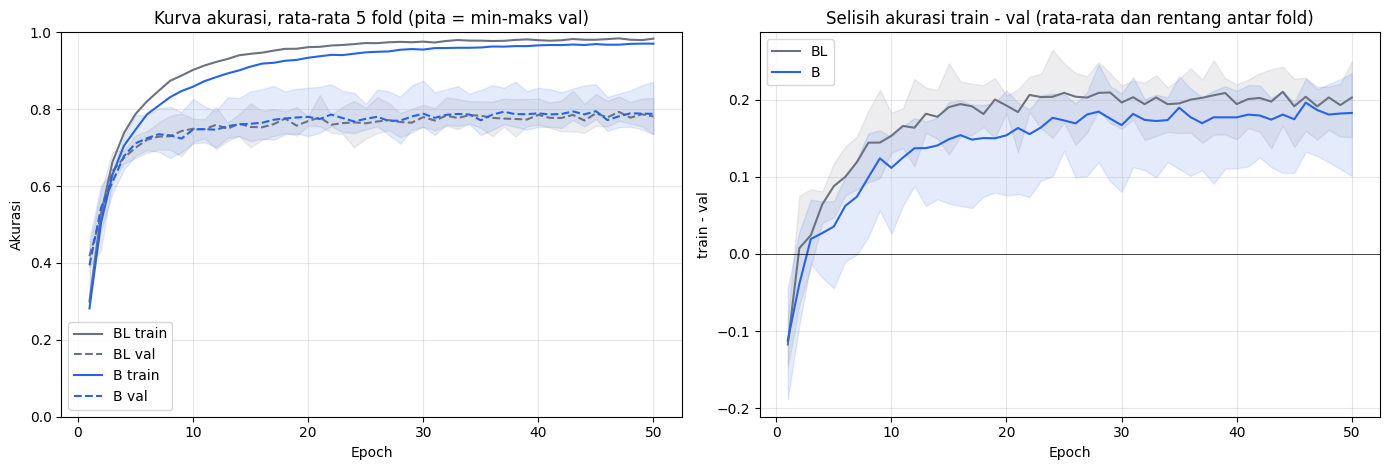

,val_terbaik_rata2,epoch_terbaik_rata2,gap_akhir_rata2,gap_tengah_rata2
BL,0.8024,31.2,0.2026,0.1955
B,0.8051,34.6,0.1827,0.1640


In [9]:
# 8.3 kurva akurasi rata-rata lintas fold (riwayat training dari notebook eksperimen)
def muat_hist(m, k):
    hs = [json.load(open(os.path.join(SRC, "history", f"{m}_fold{k}_s{s}.json"))) for s in SEEDS_ADA[m]]
    L = min(len(h["accuracy"]) for h in hs)
    return {key: np.mean([h[key][:L] for h in hs], axis=0) for key in ("accuracy", "val_accuracy")}
HIS = {m: [muat_hist(m, k) for k in range(1, N_FOLD + 1)] for m in ("BL", "B")}
L = min(len(h["accuracy"]) for m in HIS for h in HIS[m]); ep = np.arange(1, L + 1)
def agg(m, key): return np.array([h[key][:L] for h in HIS[m]])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for m in ("BL", "B"):
    tr, va = agg(m, "accuracy"), agg(m, "val_accuracy")
    ax[0].plot(ep, tr.mean(0), color=warna[m], label=f"{m} train"); ax[0].plot(ep, va.mean(0), color=warna[m], ls="--", label=f"{m} val")
    ax[0].fill_between(ep, va.min(0), va.max(0), color=warna[m], alpha=0.12)
    gap = tr - va; ax[1].plot(ep, gap.mean(0), color=warna[m], label=m); ax[1].fill_between(ep, gap.min(0), gap.max(0), color=warna[m], alpha=0.12)
ax[0].set_title(f"Kurva akurasi, rata-rata {N_FOLD} fold (pita = min-maks val)"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Akurasi"); ax[0].set_ylim(0, 1); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].set_title("Selisih akurasi train - val (rata-rata dan rentang antar fold)"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("train - val"); ax[1].axhline(0, color="k", lw=0.5); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_kurva_validasi_m3.png"), dpi=200); plt.show()

KURVA = {}
for m in ("BL", "B"):
    va = agg(m, "val_accuracy"); tr = agg(m, "accuracy")
    KURVA[m] = dict(val_terbaik_rata2=va.max(axis=1).mean(), epoch_terbaik_rata2=va.argmax(axis=1).mean() + 1,
                    gap_akhir_rata2=(tr[:, -1] - va[:, -1]).mean(), gap_tengah_rata2=(tr - va)[:, L // 5: 4 * L // 5].mean())
display(pd.DataFrame(KURVA).T.round(4))

## 9. Ringkasan hasil (kalimat dibangkitkan dari hasil di atas)
Setiap angka dan label signifikan dihitung oleh kode. Jika hasil berubah, kalimat ikut berubah.

In [10]:
def idn(x, d=2, plus=False): return (f"{x:+.{d}f}" if plus else f"{x:.{d}f}").replace(".", ",")
def sig(p): return "signifikan" if p < ALPHA else "belum signifikan"
def baris(kel, pas, metrik="Akurasi segmen"):
    return UJI[(UJI.keluarga == kel) & (UJI.perbandingan == pas) & (UJI.metrik == metrik)].iloc[0]
def mcn(kel, pas): return MCN[(MCN.keluarga == kel) & (MCN.perbandingan == pas)].iloc[0]
S = TABEL["Akurasi segmen"]; STR = TABEL["Akurasi lagu"]

print(f"1. Hasil lintas {N_FOLD} fold (akurasi segmen dan akurasi lagu, rata-rata ± SD):")
for m in S.sort_values("Rata-rata", ascending=False).index:
    print(f"   - {NAMA[m]}: {idn(S.loc[m, 'Rata-rata'])} ± {idn(S.loc[m, 'SD'])} | lagu {idn(STR.loc[m, 'Rata-rata'])} ± {idn(STR.loc[m, 'SD'])}")

def ci_kata(r): return "memuat nol" if r.ci95_bawah <= 0 <= r.ci95_atas else "tidak memuat nol"
r = baris("direncanakan", "B vs BL"); mb = mcn("direncanakan", "B vs BL")
print(f"\n2. Keluarga direncanakan. B vs BL (uji antar fold): selisih {idn(r.selisih, plus=True)} poin (CI 95% {idn(r.ci95_bawah, plus=True)} sampai {idn(r.ci95_atas, plus=True)}; CI {ci_kata(r)}); "
      f"B lebih baik di {int(r.fold_a_unggul)} dari {int(r.n_fold)} fold; t = {idn(r.t)}, p = {idn(r.p, 3)}, p Holm = {idn(r.p_holm, 3)}, d_z = {idn(r.cohen_dz)} -> {sig(r.p_holm)} pada α = {idn(ALPHA)}.")
for nm in ("F1-macro", "Akurasi lagu"):
    rr = baris("direncanakan", "B vs BL", nm); print(f"   {nm}: selisih {idn(rr.selisih, plus=True)} poin, p = {idn(rr.p, 3)} ({sig(rr.p_holm)}).")
print(f"   McNemar tingkat lagu ({len(ref)} lagu): B benar sendiri pada {int(mb.benar_hanya_a)} lagu, BL benar sendiri pada {int(mb.benar_hanya_b)} lagu; p Holm = {idn(mb.p_holm, 4)} -> {sig(mb.p_holm)}.")
if (r.p_holm < ALPHA) != (mb.p_holm < ALPHA):
    print("   Kedua uji memberi kesimpulan berbeda. Uji antar fold memperlakukan fold sebagai unit dan menangkap variasi antar-fold; McNemar memperlakukan lagu sebagai sampel independen dan "
          "hanya menilai satu model terlatih per fold, sehingga tidak menangkap variasi antar-run pelatihan. Uji antar fold dipakai sebagai kesimpulan utama.")
print("   Pendekatan A (fitur MFCC ringkas), uji antar fold:")
for pas in ("BL vs A_SVM", "BL vs A_RF", "B vs A_SVM", "B vs A_RF", "A_SVM vs A_RF"):
    rr = baris("direncanakan", pas); print(f"   - {pas}: selisih {idn(rr.selisih, plus=True)} poin, p Holm = {idn(rr.p_holm, 4)} ({sig(rr.p_holm)}), unggul di {int(rr.fold_a_unggul)} dari {int(rr.n_fold)} fold.")

print("\n3. Keluarga eksploratif (metode tambahan), dibanding baseline:")
for m in BARU:
    for nm in ("Akurasi segmen", "Akurasi lagu"):
        rr = baris("eksploratif", f"{m} vs BL", nm); arah = "lebih tinggi" if rr.selisih > 0 else "lebih rendah"
        print(f"   - {m} ({nm.lower()}, uji antar fold): {arah} {idn(abs(rr.selisih))} poin (CI 95% {idn(rr.ci95_bawah, plus=True)} sampai {idn(rr.ci95_atas, plus=True)}; CI {ci_kata(rr)}), "
              f"unggul di {int(rr.fold_a_unggul)} dari {int(rr.n_fold)} fold; p Holm = {idn(rr.p_holm, 4)} -> {sig(rr.p_holm)}.")
    mm = mcn("eksploratif", f"{m} vs BL")
    print(f"     McNemar lagu: {m} benar sendiri pada {int(mm.benar_hanya_a)} lagu, BL pada {int(mm.benar_hanya_b)} lagu; p Holm = {idn(mm.p_holm, 4)} -> {sig(mm.p_holm)}.")
lebih = [m for m in BARU if baris("eksploratif", f"{m} vs BL").selisih > 0 and baris("eksploratif", f"{m} vs BL").p_holm < ALPHA]
lebih_l = [m for m in BARU if baris("eksploratif", f"{m} vs BL", "Akurasi lagu").selisih > 0 and baris("eksploratif", f"{m} vs BL", "Akurasi lagu").p_holm < ALPHA]
print("   Kesimpulan: " + (f"akurasi segmen yang signifikan lebih baik dari BL: {', '.join(lebih)}." if lebih else "tidak ada metode tambahan yang terbukti signifikan lebih baik dari BL pada akurasi segmen.") +
      (f" Pada akurasi lagu: {', '.join(lebih_l)}." if lebih_l else " Pada akurasi lagu juga tidak ada."))
print("   Ablasi (akurasi segmen, uji antar fold):")
for pas in ("CD_GAB vs C_YAM", "CD_GAB vs D_HAND", "C_YAM vs D_HAND", "D_HAND vs A_SVM"):
    rr = baris("eksploratif", pas); print(f"   - {pas}: selisih {idn(rr.selisih, plus=True)} poin, p Holm = {idn(rr.p_holm, 4)} ({sig(rr.p_holm)}), unggul di {int(rr.fold_a_unggul)} dari {int(rr.n_fold)} fold.")

mudah, sulit = REC["BL"].idxmax(), REC["BL"].idxmin(); sel = REC["B - BL"]; sel2 = REC["CD_GAB - BL"]
print(f"\n4. Per genre: BL paling mudah pada {mudah} ({idn(REC.loc[mudah, 'BL'], 1)}%) dan paling sulit pada {sulit} ({idn(REC.loc[sulit, 'BL'], 1)}%). "
      f"B lebih baik daripada BL di {int((sel > 0).sum())} dari {len(sel)} genre (terbesar {sel.idxmax()} {idn(sel.max(), 1, True)}, terkecil {sel.idxmin()} {idn(sel.min(), 1, True)} poin). "
      f"CD_GAB lebih baik daripada BL di {int((sel2 > 0).sum())} dari {len(sel2)} genre (terbesar {sel2.idxmax()} {idn(sel2.max(), 1, True)}, terkecil {sel2.idxmin()} {idn(sel2.min(), 1, True)} poin).")
kb = KONF["BL"].iloc[0]; kc = KONF["CD_GAB"].iloc[0]
print(f"   Kesalahan terbesar BL: {kb.sebenarnya} diprediksi {kb.diprediksi} ({idn(kb.persen_kelas, 1)}% segmen {kb.sebenarnya}); CD_GAB: {kc.sebenarnya} diprediksi {kc.diprediksi} ({idn(kc.persen_kelas, 1)}%).")
tc = tum["CD_GAB"]
print(f"   Tumpang tindih BL dan CD_GAB: keduanya benar {idn(tc['keduanya benar'], 1)}%, hanya BL benar {idn(tc['hanya BL benar'], 1)}%, hanya CD_GAB benar {idn(tc['hanya CD_GAB benar'], 1)}%, keduanya salah {idn(tc['keduanya salah'], 1)}% segmen.")
tb = tum["B"]
print(f"   Tumpang tindih BL dan B: keduanya benar {idn(tb['keduanya benar'], 1)}%, hanya BL benar {idn(tb['hanya BL benar'], 1)}%, hanya B benar {idn(tb['hanya B benar'], 1)}%, keduanya salah {idn(tb['keduanya salah'], 1)}% segmen.")

kk, kb2 = KURVA["BL"], KURVA["B"]
print(f"\n5. Kurva rata-rata {N_FOLD} fold: val terbaik BL {idn(kk['val_terbaik_rata2'], 3)} (epoch rata-rata {idn(kk['epoch_terbaik_rata2'], 1)}), B {idn(kb2['val_terbaik_rata2'], 3)} (epoch {idn(kb2['epoch_terbaik_rata2'], 1)}). "
      f"Selisih train-val pada pertengahan pelatihan: BL {idn(kk['gap_tengah_rata2'], 3)}, B {idn(kb2['gap_tengah_rata2'], 3)}; pada epoch terakhir: BL {idn(kk['gap_akhir_rata2'], 3)}, B {idn(kb2['gap_akhir_rata2'], 3)}.")

1. Hasil lintas 5 fold (akurasi segmen dan akurasi lagu, rata-rata ± SD):
   - CD_GAB (gabungan+SVM): 83,19 ± 2,34 | lagu 90,29 ± 2,01
   - B (BL+SpecAug+LS): 82,10 ± 1,57 | lagu 86,54 ± 2,15
   - BL (CNN+Bi-GRU): 81,34 ± 1,07 | lagu 86,34 ± 1,66
   - C_YAM (YAMNet+SVM): 78,95 ± 2,73 | lagu 86,19 ± 2,99
   - D_HAND (buatan tangan+SVM): 74,68 ± 1,15 | lagu 82,78 ± 2,27
   - A_SVM (MFCC+SVM): 67,08 ± 2,75 | lagu 76,67 ± 3,42
   - A_RF (MFCC+RF): 64,82 ± 3,03 | lagu 71,47 ± 3,09

2. Keluarga direncanakan. B vs BL (uji antar fold): selisih +0,75 poin (CI 95% -0,61 sampai +2,12; CI memuat nol); B lebih baik di 4 dari 5 fold; t = 1,53, p = 0,200, p Holm = 0,200, d_z = 0,69 -> belum signifikan pada α = 0,05.
   F1-macro: selisih +0,75 poin, p = 0,205 (belum signifikan).
   Akurasi lagu: selisih +0,20 poin, p = 0,803 (belum signifikan).
   McNemar tingkat lagu (999 lagu): B benar sendiri pada 44 lagu, BL benar sendiri pada 52 lagu; p Holm = 0,4752 -> belum signifikan.
   Pendekatan A (fitur MF

## 10. Keterbatasan dan konsistensi (dibangkitkan dari hasil)

In [11]:
nseed = {m: len(SEEDS_ADA[m]) for m in ("BL", "B")}
sel_rata = abs(baris("direncanakan", "B vs BL").selisih)
print("Keterbatasan:")
print(f"1. Hanya {N_FOLD} fold: uji antar fold berderajat kebebasan {N_FOLD - 1}, dan p terkecil uji Wilcoxon adalah {idn(2 / 2 ** N_FOLD, 4)} "
      f"({'tidak' if 2 / 2 ** N_FOLD >= ALPHA else 'dapat'} mencapai α = {idn(ALPHA)}). Data latih antar fold saling tumpang tindih sehingga p-value cenderung optimistis. "
      f"Koreksi Holm diterapkan per keluarga ({len(PLAN)} perbandingan direncanakan, {len(EKSPL)} eksploratif).")
if max(nseed.values()) > 1:
    per = semua_raw[semua_raw.metode.isin(["BL", "B"])].groupby(["metode", "fold"]).test_acc.agg(lambda s: (s.max() - s.min()) * 100).groupby("metode").mean()
    print(f"2. Dengan {max(nseed.values())} seed, rentang akurasi antar seed pada fold yang sama rata-rata {idn(per['BL'])} poin (BL) dan {idn(per['B'])} poin (B), "
          f"dibandingkan selisih rata-rata B vs BL {idn(sel_rata)} poin; GPU tidak sepenuhnya deterministik sehingga run ulang dapat sedikit berbeda.")
else:
    print(f"2. Satu seed per fold untuk BL dan B. GPU tidak sepenuhnya deterministik, sehingga pengulangan konfigurasi yang sama dapat memberi hasil yang sedikit berbeda; "
          f"selisih B vs BL ({idn(sel_rata)} poin) perlu ditafsirkan dengan mempertimbangkan derau ini.")
print("3. B mengubah dua faktor sekaligus (SpecAugment dan label smoothing); kontribusi masing-masing tidak dapat dipisahkan dari data ini.")
print(f"4. Uji McNemar ({len(ref)} lagu) hanya menilai satu model terlatih per fold dan memperlakukan lagu sebagai sampel independen.")
print("5. Prediksi lagu pada uji McNemar memakai voting mayoritas segmen, sedangkan akurasi lagu pada tabel memakai rata-rata probabilitas; angka keduanya dapat berbeda sedikit.")
print(f"6. Setiap kotak pada boxplot dibuat dari {N_FOLD} nilai fold; sebaran bersifat deskriptif.")
print("7. Metode C, D, dan CD bersifat eksploratif (dirancang setelah hasil awal diketahui); C_YAM memakai model yang dilatih pada data eksternal dengan ontologi yang memuat kategori genre musik, "
      "sehingga perbandingannya bukan 'dari nol'. Metode klasik memakai CPU dan seed tetap (deterministik), sedangkan BL dan B memakai GPU.")
print("8. Pembagian fold berasal dari satu skema pembagian (seed tetap); sensitivitas terhadap seed pembagian tidak diuji.")

f02 = os.path.join(SRC, "tabel_m2_ringkasan.csv")      # konsistensi dengan ringkasan notebook eksperimen
if os.path.exists(f02):
    a = pd.read_csv(f02, index_col=0); ok = True
    for m in METODE:
        b = RINGKAS.loc[NAMA[m]]; aa = a.loc[NAMA[m]]
        ok &= all(b[c] == aa[c] for c in a.columns if c in b.index)
    print("\nKonsistensi dengan ringkasan notebook eksperimen:", "SAMA persis" if ok else "BERBEDA, periksa sumber hasil")
else:
    print("\nRingkasan notebook eksperimen tidak ditemukan; pemeriksaan konsistensi dilewati.")

def ver(p):
    try: return md.version(p)
    except Exception: return "tidak terpasang"
print("Versi paket:", ", ".join(f"{p}=={ver(p)}" for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]), "| Python", platform.python_version())
print("Sumber hasil:", SRC)

Keterbatasan:
1. Hanya 5 fold: uji antar fold berderajat kebebasan 4, dan p terkecil uji Wilcoxon adalah 0,0625 (tidak mencapai α = 0,05). Data latih antar fold saling tumpang tindih sehingga p-value cenderung optimistis. Koreksi Holm diterapkan per keluarga (6 perbandingan direncanakan, 9 eksploratif).
2. Dengan 2 seed, rentang akurasi antar seed pada fold yang sama rata-rata 2,06 poin (BL) dan 1,39 poin (B), dibandingkan selisih rata-rata B vs BL 0,75 poin; GPU tidak sepenuhnya deterministik sehingga run ulang dapat sedikit berbeda.
3. B mengubah dua faktor sekaligus (SpecAugment dan label smoothing); kontribusi masing-masing tidak dapat dipisahkan dari data ini.
4. Uji McNemar (999 lagu) hanya menilai satu model terlatih per fold dan memperlakukan lagu sebagai sampel independen.
5. Prediksi lagu pada uji McNemar memakai voting mayoritas segmen, sedangkan akurasi lagu pada tabel memakai rata-rata probabilitas; angka keduanya dapat berbeda sedikit.
6. Setiap kotak pada boxplot dibuat 

In [12]:
isi = ["uji_berpasangan_m3.csv", "uji_mcnemar_m3.csv", "tabel_m3_ringkasan.csv", "tabel_m3_recall_per_genre.csv", "tabel_m3_tumpang_tindih.csv",
       "tabel_m3_konfusi_BL.csv", "tabel_m3_konfusi_B.csv", "tabel_m3_konfusi_CD_GAB.csv", "fig_confusion_m3.png", "fig_boxplot_f1_genre.png",
       "fig_boxplot_metrik_fold.png", "fig_kurva_validasi_m3.png"] + [f"tabel_m3_{c}.csv" for c in METRIK]
with zipfile.ZipFile(os.path.join(WORK_DIR, "hasil_minggu3.zip"), "w", zipfile.ZIP_DEFLATED) as z:
    for nm in isi:
        pth = os.path.join(WORK_DIR, nm)
        if os.path.exists(pth): z.write(pth, nm)
print("hasil_minggu3.zip siap diunduh")

hasil_minggu3.zip siap diunduh
